# A molecule in an electric field

What happens to a molecule in a uniform electric field? The electrons move against the
field. So the molecule gets a dipole, and the two atoms feel opposite forces. Here we put
the CO molecule in a field along its axis and compute three things: the dipole, the
polarizability, and the force on the bond.

A uniform field is not periodic. So the code adds a saw-tooth potential, as `pw.x` does.
It rises linearly through the molecule and falls back in the vacuum, in a thin region of
width `eopreg`. We also switch on the dipole correction (`dipfield`). It removes the
field that the dipole of the molecule creates through its periodic images.

The energy of the field, for the electrons and the ions together, is:

$$E_f = \frac{\Omega}{4\pi}\,e^2\Big[-E\,D + \tfrac12 D^2\Big],\qquad
\frac{\Omega}{4\pi}D = \sum_a Z_a z_a - \int n(\mathbf r)\,z\,d\mathbf r .$$

Here $z$ is measured along the saw-tooth. So $\Omega D/4\pi$ is the dipole of the cell,
in $e\cdot$bohr. The potential and the forces are derivatives of this one energy.

Against `pw.x` on the same input, the total energy agrees to 4e-10 Ry and the force to
4e-7 Ry/bohr.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from defuqumat import Calculator
from defuqumat.io import comparison_table, read_qe_output

CASES, PSEUDO = Path("../tests/data/qe"), Path("../tests/data/pseudo")
TEXT = (CASES / "efield-co-dipole.in").read_text()
warnings.filterwarnings("ignore", message="tefield")   # no symmetry with a field, as in pw.x

calc = Calculator.from_text(TEXT, pseudo_dir=PSEUDO, announce=False)
scf = calc.get_scf()
print("E = %.10f Ry,  dipole = %+.5f e bohr" % (scf.total_energy, scf.efield_dipole))

E = -43.1230004596 Ry,  dipole = -0.03377 e bohr


## The same numbers in `pw.x`

The input is `pw_relax/relax-el.in` from the test suite of Quantum ESPRESSO, with
`dipfield` added: CO in a 10 bohr cube, ultrasoft pseudopotentials, a field of
0.001 Ha a.u. (0.51 V/nm) along $z$. Both codes run at `conv_thr = 1e-13`, because a cell
that is mostly vacuum converges its forces slowly.

In [2]:
qe = read_qe_output(CASES / "reference.out.efield-co-dipole")
force = calc.get_forces().forces
rows = [("total energy [Ry]", scf.total_energy, qe.total_energy),
        ("field energy [Ry]", scf.efield_energy, qe.energy_terms["efield"]),
        ("force on O, z [Ry/bohr]", force[0, 2], qe.forces[0, 2])]
print(comparison_table(rows, fmt="{:.8f}", headers=("", "defuqumat", "pw.x", "difference")))

                            defuqumat          pw.x  difference
total energy [Ry]        -43.12300046  -43.12300046     3.6e-10
field energy [Ry]          0.00008187    0.00008187     2.8e-09
force on O, z [Ry/bohr]    0.11697173    0.11697193     2.0e-07


## The dipole grows with the field

We now run the same molecule at five field strengths. The slope of the dipole is the
polarizability along the bond, $\alpha_{zz} = \partial p_z/\partial E$, in bohr$^3$.

In [3]:
FIELDS = np.array([-0.004, -0.002, 0.0, 0.002, 0.004])   # Ha a.u.
runs = []
for eamp in FIELDS:
    c = Calculator.from_text(TEXT.replace("eamp=0.001", f"eamp={eamp}"),
                             pseudo_dir=PSEUDO, announce=False, conv_thr=1e-10)
    runs.append((c.get_scf(), c.get_forces().forces[0, 2]))
dipole = np.array([r.efield_dipole for r, _ in runs])
alpha = np.polyfit(FIELDS, dipole, 1)[0]
print("alpha_zz = %.2f bohr^3" % alpha)
for e, (r, f) in zip(FIELDS, runs):
    print("E = %+.3f   p = %+.5f e bohr   F(O) = %+.6f Ry/bohr" % (e, r.efield_dipole, f))

alpha_zz = 13.50 bohr^3
E = -0.004   p = -0.10138 e bohr   F(O) = +0.122152 Ry/bohr
E = -0.002   p = -0.07429 e bohr   F(O) = +0.120131 Ry/bohr
E = +0.000   p = -0.04727 e bohr   F(O) = +0.118047 Ry/bohr
E = +0.002   p = -0.02027 e bohr   F(O) = +0.115882 Ry/bohr
E = +0.004   p = +0.00662 e bohr   F(O) = +0.113682 Ry/bohr


The measured static polarizability of CO along the bond is about 15.6 bohr$^3$. The
number here is for a molecule in a 10 bohr box at 25 Ry, so it is a rough estimate. The
box is small, and the density of the molecule still overlaps its images.

The force on the oxygen changes linearly with the field. The field pushes the positive
ions along $+z$ and the electrons along $-z$, so it stretches or compresses the bond. A
relaxation in the field (`calc.get_relax()`) finds the new bond length.

## Where the charge goes

The figure shows the change of the electron density, averaged over the $xy$ plane, when
the field goes from 0 to 0.004 Ha a.u. The electrons move to the side of lower potential
energy. The dashed line is the saw-tooth potential that the electrons feel. It falls back
in the vacuum, between $z = 0.5$ and $0.6$ of the cell, far from the molecule.

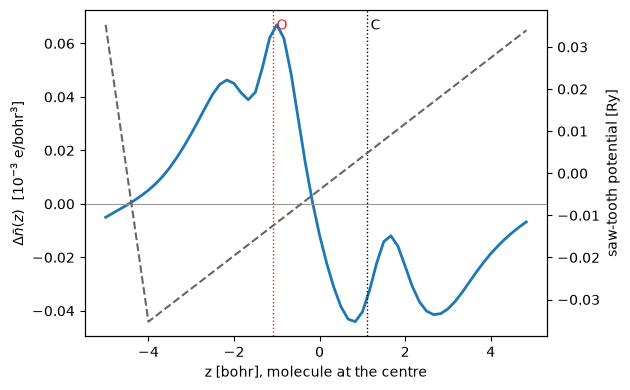

In [4]:
rho = [np.asarray(r.density).sum(axis=0).mean(axis=(0, 1)) for r, _ in runs]
nz = rho[0].size
L = float(calc.system.cell.at[2, 2])
z = np.arange(nz) / nz * L
shift = (np.arange(nz) + nz // 2) % nz          # the molecule in the middle of the plot
zplot = (z - L / 2)

fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.plot(zplot, (rho[4] - rho[2])[shift] * 1e3, color="tab:blue", lw=2)
ax.axhline(0, color="0.6", lw=0.8)
ax.set_xlabel("z [bohr], molecule at the centre")
ax.set_ylabel(r"$\Delta \bar n(z)$  [$10^{-3}$ e/bohr$^3$]")
ax.axvline(-1.1, color="tab:red", ls=":", lw=1)
ax.axvline(1.1, color="k", ls=":", lw=1)
ax.text(-1.1, ax.get_ylim()[1] * 0.9, " O", color="tab:red")
ax.text(1.1, ax.get_ylim()[1] * 0.9, " C")
drop = 0.004 - 4 * np.pi * runs[4][0].efield_dipole / float(calc.system.cell.volume)
saw = 2 * drop * np.where((z / L - 0.5) % 1 <= 0.1, (0.5 - ((z / L - 0.5) % 1) / 0.1) * 0.9,
                          (-0.5 + (((z / L - 0.5) % 1) - 0.1) / 0.9) * 0.9) * L
twin = ax.twinx()
twin.plot(zplot, saw[shift], "--", color="0.4")
twin.set_ylabel("saw-tooth potential [Ry]")
fig.tight_layout()

## What to remember

- `tefield` puts a uniform field into a periodic cell as a saw-tooth, and `dipfield`
  removes the field of the dipole of the cell itself. The drop of the saw-tooth must be in
  the vacuum.
- The energy of the field is part of the total energy, and the forces include it. So a
  relaxation in a field works, and the dipole is the derivative of the energy with
  respect to the field.
- The stress is not available with this field, as in `pw.x`.

The checks against `pw.x`, and the check that $\partial E/\partial E_{\rm amp}$ is the
dipole, are in `tests/regression/test_sawtooth.py`.